In [1]:
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from torchvision import datasets, transforms
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import DataLoader, Subset
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tqdm.auto import tqdm
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from sklearn.datasets import load_digits

digits = load_digits()

# Use 100 images for a quick experiment
images = []
true_labels = []

for i in range(100):
    image_array = (digits.images[i] / 16 * 255).astype(np.uint8)
    pil_image = Image.fromarray(image_array).convert("RGB")
    images.append(pil_image)
    true_labels.append(int(digits.target[i]))

print("Dataset loaded successfully!")
print("Number of images:", len(images))
print("Image size:", images[0].size)
print("Classes:", sorted(set(true_labels)))

Dataset loaded successfully!
Number of images: 100
Image size: (8, 8)
Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


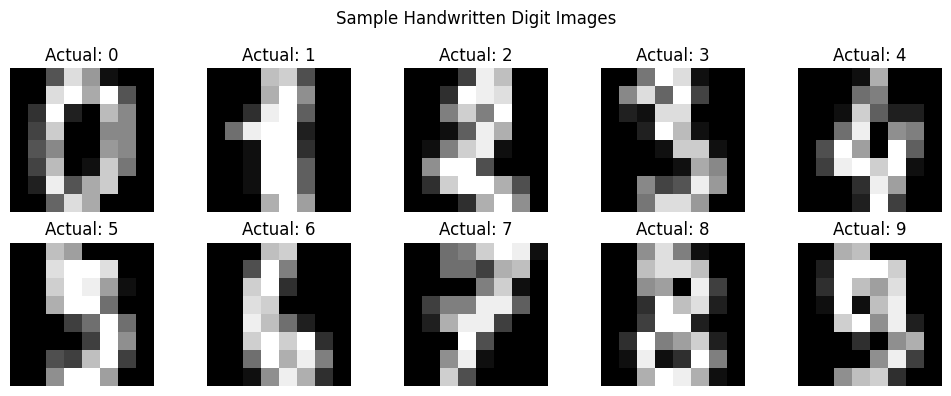

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].convert("L"), cmap="gray")
    ax.set_title(f"Actual: {true_labels[i]}")
    ax.axis("off")

plt.suptitle("Sample Handwritten Digit Images")
plt.tight_layout()
plt.show()

In [4]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

vit_name = "google/vit-base-patch16-224"

print("Loading ViT model...")

vit_processor = AutoImageProcessor.from_pretrained(vit_name)

vit_model = AutoModelForImageClassification.from_pretrained(
    vit_name
)

vit_model = vit_model.to(device)
vit_model.eval()

print("ViT model loaded successfully!")

Loading ViT model...


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

NameError: name 'device' is not defined

In [5]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vit_model = vit_model.to(device)
vit_model.eval()

print("Device:", device)
print("ViT model loaded successfully!")

Device: cpu
ViT model loaded successfully!


In [6]:
from torchvision.models import resnet50, ResNet50_Weights

print("Loading ResNet-50 CNN...")

cnn_weights = ResNet50_Weights.DEFAULT
cnn_model = resnet50(weights=cnn_weights)

cnn_model = cnn_model.to(device)
cnn_model.eval()

cnn_transform = cnn_weights.transforms()
cnn_categories = cnn_weights.meta["categories"]

print("CNN model loaded successfully!")
print("Device:", device)

Loading ResNet-50 CNN...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 67.5MB/s]


CNN model loaded successfully!
Device: cpu


In [7]:
# Convert images into the correct format
vit_inputs = vit_processor(
    images=images,
    return_tensors="pt"
)

cnn_inputs = torch.stack([
    cnn_transform(img) for img in images
])

print("ViT input shape:", vit_inputs["pixel_values"].shape)
print("CNN input shape:", cnn_inputs.shape)
print("Actual labels:", true_labels[:10])
print("Images prepared successfully!")

ViT input shape: torch.Size([100, 3, 224, 224])
CNN input shape: torch.Size([100, 3, 224, 224])
Actual labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Images prepared successfully!


In [8]:
vit_predictions = []

vit_start = time.time()

with torch.no_grad():
    for start in range(0, len(images), 8):
        batch = {
            key: value[start:start + 8].to(device)
            for key, value in vit_inputs.items()
        }

        outputs = vit_model(**batch)
        predicted_ids = outputs.logits.argmax(dim=1).cpu().tolist()

        for pred_id in predicted_ids:
            label = vit_model.config.id2label[pred_id]
            vit_predictions.append(label)

vit_time = time.time() - vit_start

print("ViT classification completed!")
print("Total images:", len(vit_predictions))
print("Inference time:", round(vit_time, 2), "seconds")
print("First 10 predictions:", vit_predictions[:10])

ViT classification completed!
Total images: 100
Inference time: 114.95 seconds
First 10 predictions: ['letter opener, paper knife, paperknife', 'letter opener, paper knife, paperknife', 'hatchet', 'screw', 'hatchet', 'hatchet', 'hatchet', 'hatchet', 'hatchet', 'pick, plectrum, plectron']


In [9]:
cnn_predictions = []

cnn_start = time.time()

with torch.no_grad():
    for start in range(0, len(images), 8):
        batch = cnn_inputs[start:start + 8].to(device)

        outputs = cnn_model(batch)
        predicted_ids = outputs.argmax(dim=1).cpu().tolist()

        for pred_id in predicted_ids:
            label = cnn_categories[pred_id]
            cnn_predictions.append(label)

cnn_time = time.time() - cnn_start

print("CNN classification completed!")
print("Total images:", len(cnn_predictions))
print("Inference time:", round(cnn_time, 2), "seconds")
print("First 10 predictions:", cnn_predictions[:10])

CNN classification completed!
Total images: 100
Inference time: 39.26 seconds
First 10 predictions: ['oboe', 'oboe', 'oboe', 'oboe', 'oboe', 'cleaver', 'oboe', 'oboe', 'oboe', 'cleaver']


In [10]:
comparison = pd.DataFrame({
    "Model": ["Vision Transformer (ViT)", "ResNet-50 CNN"],
    "Images Tested": [len(images), len(images)],
    "Inference Time (seconds)": [
        round(vit_time, 2),
        round(cnn_time, 2)
    ],
    "Time per Image (seconds)": [
        round(vit_time / len(images), 3),
        round(cnn_time / len(images), 3)
    ]
})

display(comparison)

speedup = vit_time / cnn_time
print(f"CNN was {speedup:.2f}x faster than ViT on this CPU.")

,Model,Images Tested,Inference Time (seconds),Time per Image (seconds)
0,Vision Transformer (ViT),100,114.95,1.150
1,ResNet-50 CNN,100,39.26,0.393


CNN was 2.93x faster than ViT on this CPU.


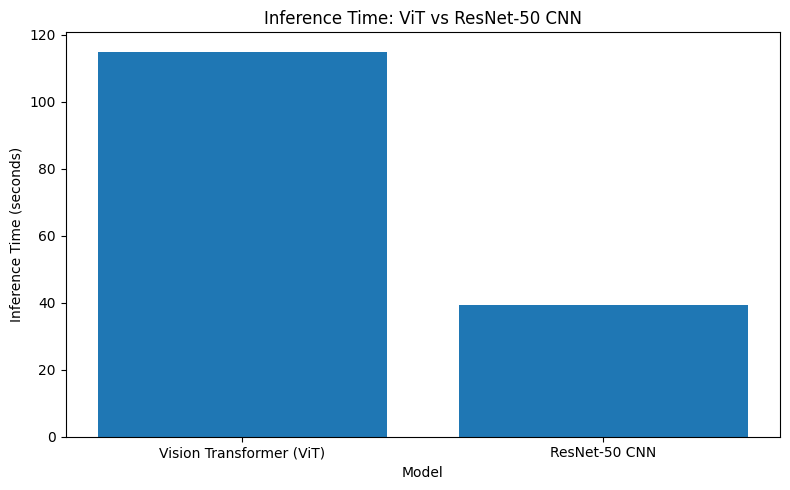

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Inference Time (seconds)"]
)

plt.title("Inference Time: ViT vs ResNet-50 CNN")
plt.ylabel("Inference Time (seconds)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

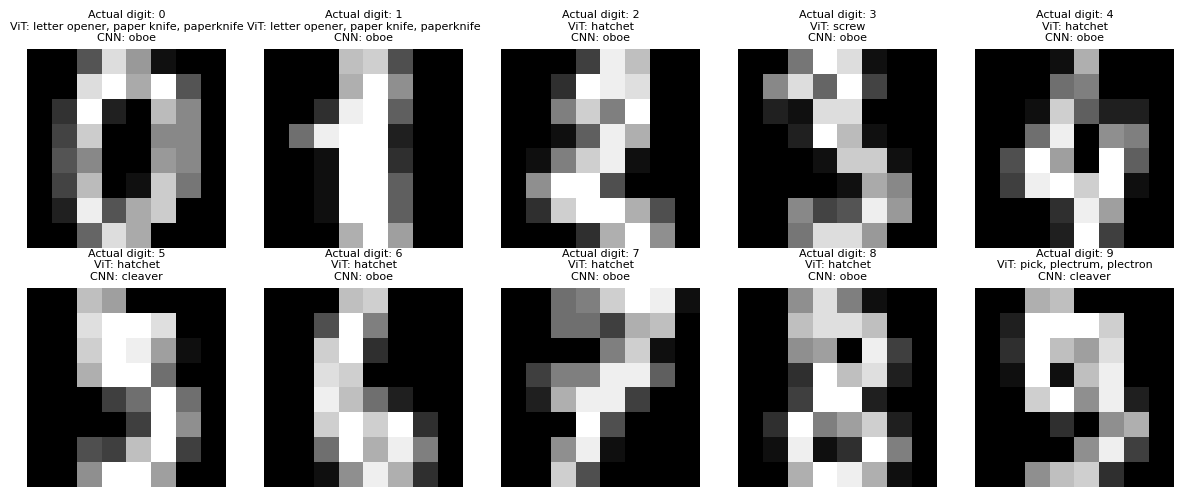

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].convert("L"), cmap="gray")
    ax.set_title(
        f"Actual digit: {true_labels[i]}\n"
        f"ViT: {vit_predictions[i]}\n"
        f"CNN: {cnn_predictions[i]}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
print("FINAL COMPARISON")
print("-" * 40)
print(f"ViT inference time: {vit_time:.2f} seconds")
print(f"CNN inference time: {cnn_time:.2f} seconds")
print(f"CNN speed advantage: {vit_time / cnn_time:.2f}x")
print()
print("Conclusion:")
print("ResNet-50 was faster than ViT on the tested CPU.")
print("ViT uses self-attention to process image patches.")
print("CNN uses convolutional layers to extract visual features.")
print(
    "Since both models retain their ImageNet classification heads, "
    "these results compare inference speed, not digit-classification accuracy."
)

FINAL COMPARISON
----------------------------------------
ViT inference time: 114.95 seconds
CNN inference time: 39.26 seconds
CNN speed advantage: 2.93x

Conclusion:
ResNet-50 was faster than ViT on the tested CPU.
ViT uses self-attention to process image patches.
CNN uses convolutional layers to extract visual features.
Since both models retain their ImageNet classification heads, these results compare inference speed, not digit-classification accuracy.
